# Taller Final – Segmentación de Clientes con K-Means

**Dataset:** Mall Customers (Kaggle – *Customer Segmentation Tutorial in Python*)

**Objetivo general:** desarrollar un modelo de segmentación de clientes con K-Means, evaluarlo con el
método del codo y el coeficiente de silueta, e interpretar los grupos desde una perspectiva de negocio
para apoyar decisiones de marketing. El despliegue interactivo está en `app.py` (Streamlit).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1 – Exploración de Datos

### 1. Cargar el dataset

> El archivo descargado tiene extensión `.xls`, pero internamente es un CSV, por eso se lee con `pd.read_csv`.

In [2]:
df = pd.read_csv("Mall_Customers.xls")
df = df.rename(columns={
    "Annual Income (k$)": "Ingreso",
    "Spending Score (1-100)": "Gasto",
    "Age": "Edad",
    "Gender": "Genero",
})
print(df.shape)
df.head()

(200, 5)


,CustomerID,Genero,Edad,Ingreso,Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
print("\nValores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerID  200 non-null    int64
 1   Genero      200 non-null    str  
 2   Edad        200 non-null    int64
 3   Ingreso     200 non-null    int64
 4   Gasto       200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Valores nulos: 0
Filas duplicadas: 0


### 2. Identificar variables relevantes

| Variable | Tipo | Descripción | ¿Útil para segmentar? |
|---|---|---|---|
| `CustomerID` | Identificador | Código único del cliente | No (no aporta información de comportamiento) |
| `Genero` | Categórica | Male / Female | Poco (se usa como descriptor del perfil) |
| `Edad` | Numérica | Edad en años | Complementaria |
| `Ingreso` | Numérica | Ingreso anual (miles de USD) | **Sí** |
| `Gasto` | Numérica | Puntaje de gasto asignado por el centro comercial (1–100) | **Sí** |

### 3. Análisis descriptivo básico

In [4]:
df.describe().round(2)

,CustomerID,Edad,Ingreso,Gasto
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [5]:
df['Genero'].value_counts()

Genero
Female    112
Male       88
Name: count, dtype: int64

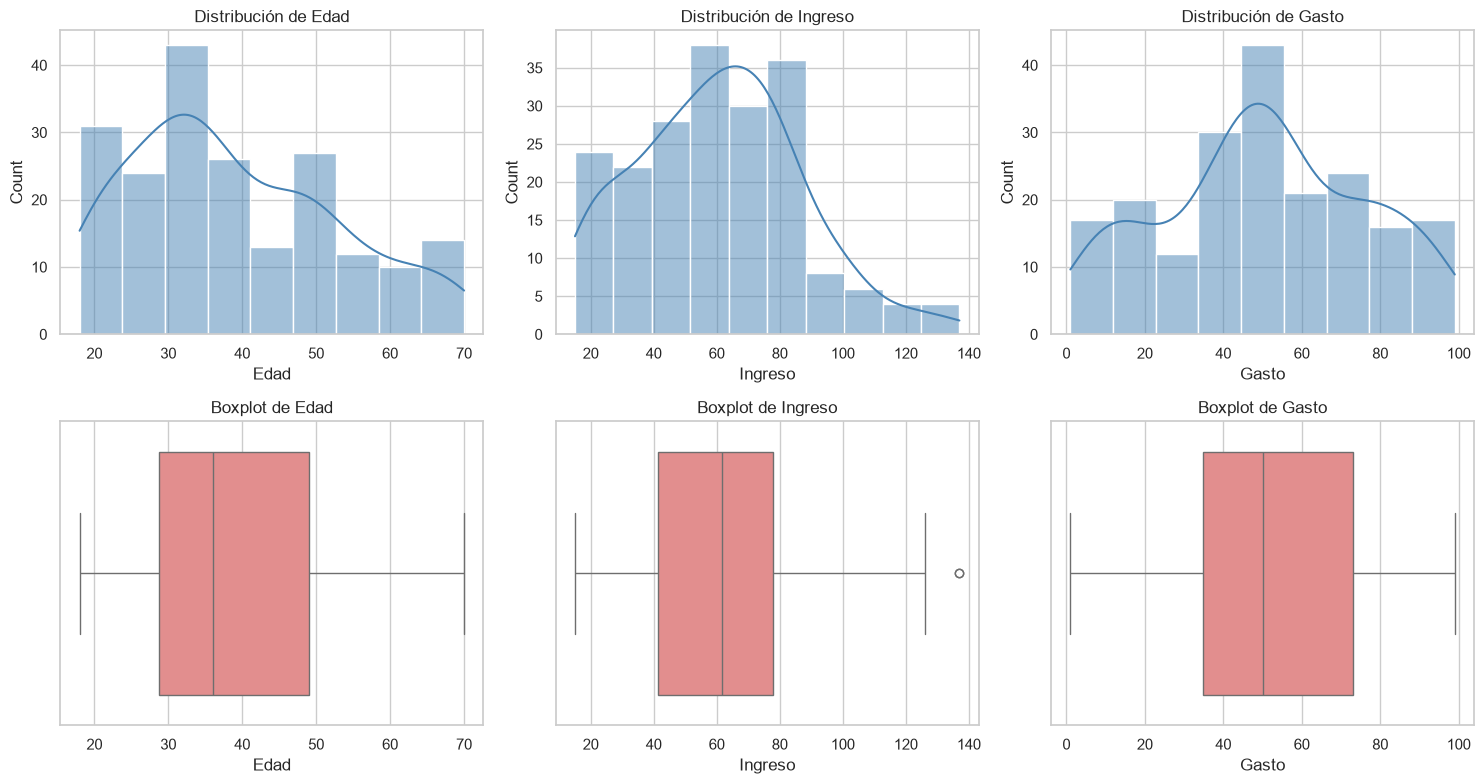

In [6]:
num_cols = ["Edad", "Ingreso", "Gasto"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Distribución de {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="lightcoral")
    axes[1, i].set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

In [7]:
# Detección de atípicos con la regla del rango intercuartílico (IQR)
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col:8s} -> límites [{lim_inf:.1f}, {lim_sup:.1f}] | atípicos: {len(atipicos)} {atipicos[col].tolist()}")

Edad     -> límites [-1.6, 79.4] | atípicos: 0 []
Ingreso  -> límites [-13.2, 132.8] | atípicos: 2 [137, 137]
Gasto    -> límites [-22.6, 130.4] | atípicos: 0 []


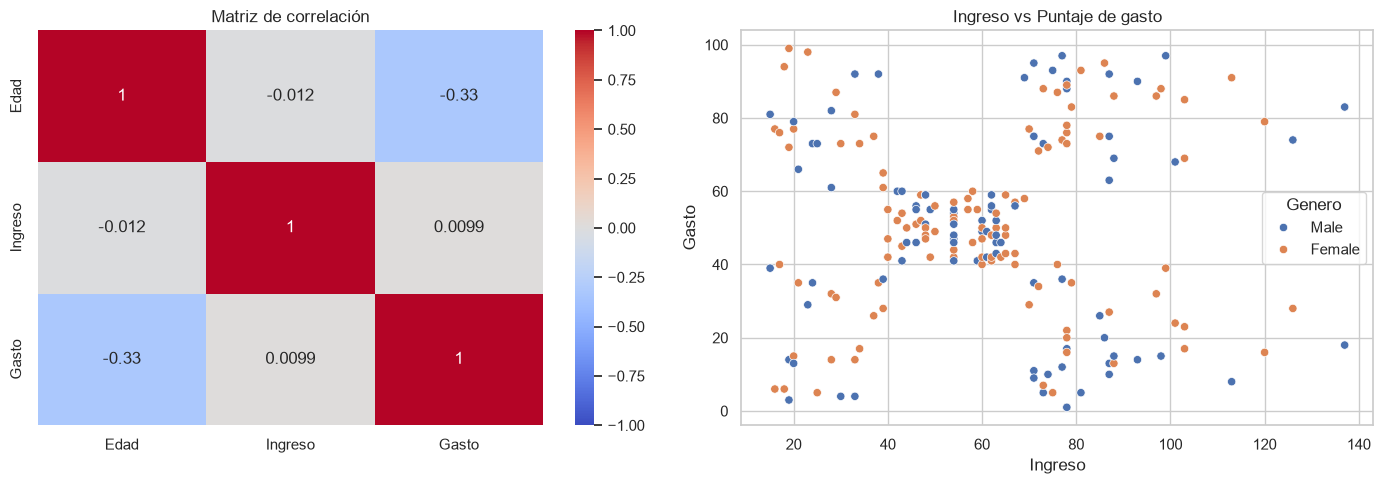

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Matriz de correlación")
sns.scatterplot(data=df, x="Ingreso", y="Gasto", hue="Genero", ax=axes[1])
axes[1].set_title("Ingreso vs Puntaje de gasto")
plt.tight_layout()
plt.show()

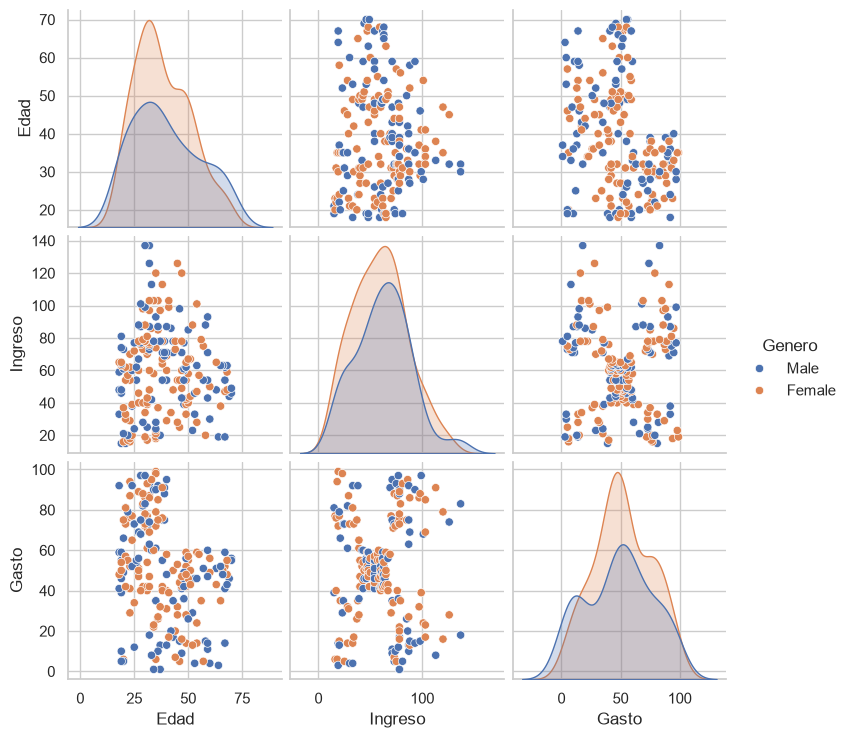

In [9]:
sns.pairplot(df[num_cols + ["Genero"]], hue="Genero", diag_kind="kde")
plt.show()

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

`Ingreso` (ingreso anual) y `Gasto` (puntaje de gasto). Juntas describen *capacidad de compra* y
*comportamiento de compra*, que es exactamente lo que interesa a marketing. Además, el diagrama de
dispersión Ingreso vs Gasto muestra a simple vista grupos bien separados (forma de "X" con cinco nubes).
`CustomerID` se descarta por ser un identificador; `Genero` es categórica y su distribución es muy
parecida entre grupos, así que se usa solo para describir los perfiles; `Edad` se usa como variable
descriptiva para interpretar los clusters (incluirla diluye la separación en el plano Ingreso–Gasto).

**¿Se identifican valores atípicos?**

Muy pocos. Con la regla IQR solo aparecen **2 registros con ingreso de 137 k$** (por encima del límite
superior de 132.75 k$). `Edad` y `Gasto` no presentan atípicos. Esos dos clientes son valores reales y
plausibles (clientes de ingreso muy alto), no errores de captura, por lo que se conservan. El dataset
tampoco tiene nulos ni duplicados.

**¿Qué tipo de relaciones se observan entre las variables?**

- `Ingreso` y `Gasto` prácticamente **no tienen correlación lineal** (≈ 0.01), pero sí una **estructura de
  grupos** clara: la relación no es lineal sino por segmentos, lo que justifica usar clustering.
- `Edad` y `Gasto` tienen una **correlación negativa moderada** (≈ −0.33): los clientes jóvenes tienden a
  tener puntajes de gasto más altos; los puntajes muy altos (> 60) se concentran en menores de 40 años.
- `Edad` e `Ingreso` no están relacionadas (≈ −0.01).
- Hay más mujeres (112) que hombres (88), pero las distribuciones por género son similares.

## Parte 2 – Preprocesamiento

In [10]:
FEATURES = ["Ingreso", "Gasto"]
X = df[FEATURES].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=FEATURES).describe().round(2)

,Ingreso,Gasto
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**. Si las variables
están en escalas distintas (por ejemplo ingreso de 15 a 137 frente a gasto de 1 a 100, o peor aún, ingresos
en dólares vs. edades), la variable con mayor rango domina el cálculo de la distancia y el algoritmo
termina agrupando casi solo por ella. `StandardScaler` transforma cada variable a media 0 y desviación
estándar 1, de modo que **todas contribuyen por igual** a la distancia. Además, la inercia y la silueta
se vuelven comparables y la convergencia es más estable.

## Parte 3 – Método del Codo

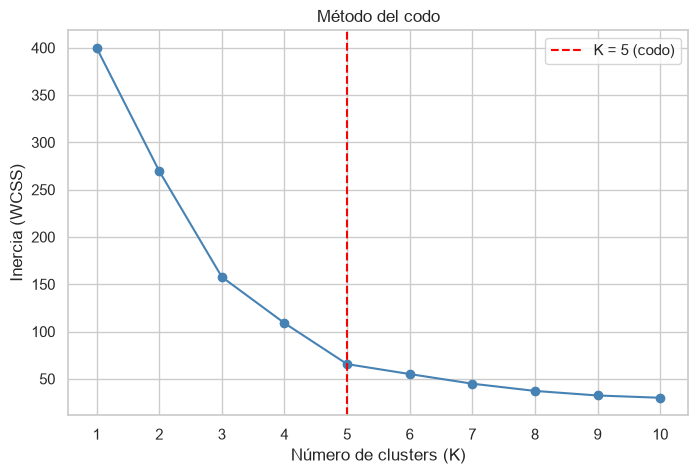

,K,Inercia,Reducción vs K-1
0,1,400.00,NaN
1,2,269.69,130.31
2,3,157.70,111.99
3,4,108.92,48.78
4,5,65.57,43.35
5,6,55.06,10.51
6,7,44.86,10.19
7,8,37.23,7.64
8,9,32.39,4.84
9,10,29.98,2.41


In [11]:
K_RANGE = range(1, 11)
inercias = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inercias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), inercias, "o-", color="steelblue")
plt.axvline(5, ls="--", color="red", label="K = 5 (codo)")
plt.title("Método del codo")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.xticks(list(K_RANGE))
plt.legend()
plt.show()

pd.DataFrame({"K": list(K_RANGE), "Inercia": np.round(inercias, 2),
              "Reducción vs K-1": np.round([np.nan] + list(-np.diff(inercias)), 2)})

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia (WCSS, *Within-Cluster Sum of Squares*) es la suma de las distancias al cuadrado de cada punto a
su centroide. Un valor cercano a cero significa que los puntos están **muy próximos a su centroide**, es
decir, los clusters son compactos y homogéneos internamente. Sin embargo, la inercia siempre disminuye al
aumentar K (con K = n sería exactamente 0, un cluster por cliente, lo cual es inútil). Por eso no se busca
el mínimo absoluto, sino el punto donde agregar clusters deja de reducir la inercia de forma significativa.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **"codo"** de la curva: el valor de K a partir del cual la pendiente se aplana. En la tabla se
ve que de K = 4 a K = 5 la inercia cae ≈ 43 unidades (108.9 → 65.6), mientras que de K = 5 a K = 6 solo
cae ≈ 10 (65.6 → 55.1) y luego las reducciones son cada vez menores. Por lo tanto el codo está en
**K = 5**: es el punto de equilibrio entre compacidad de los grupos y simplicidad del modelo.

## Parte 4 – Coeficiente de Silueta

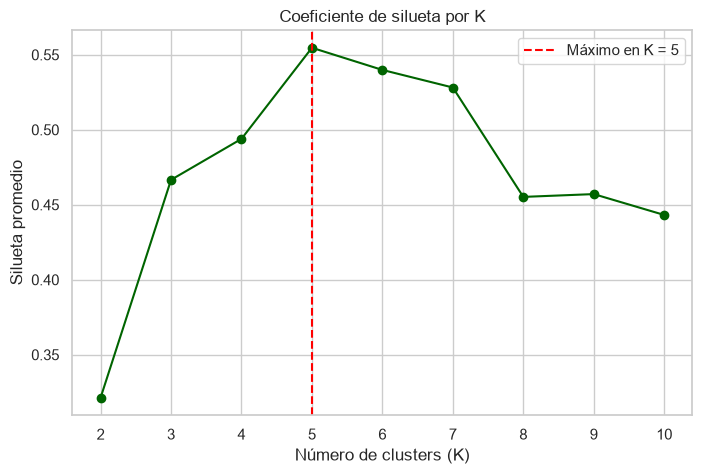

K óptimo según silueta: 5


,Silueta
2,0.321
3,0.467
4,0.494
5,0.555
6,0.540
7,0.528
8,0.455
9,0.457
10,0.443


In [12]:
siluetas = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    siluetas[k] = silhouette_score(X_scaled, km.labels_)

k_best = max(siluetas, key=siluetas.get)

plt.figure(figsize=(8, 5))
plt.plot(list(siluetas.keys()), list(siluetas.values()), "o-", color="darkgreen")
plt.axvline(k_best, ls="--", color="red", label=f"Máximo en K = {k_best}")
plt.title("Coeficiente de silueta por K")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silueta promedio")
plt.legend()
plt.show()

print("K óptimo según silueta:", k_best)
pd.Series(siluetas, name="Silueta").round(3).to_frame()

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**

Para cada punto *i* compara la distancia media a los puntos de su propio cluster, *a(i)* (cohesión), con la
distancia media al cluster vecino más cercano, *b(i)* (separación):

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}, \qquad -1 \le s(i) \le 1$$

El coeficiente del modelo es el promedio de *s(i)*. Mide simultáneamente **qué tan compactos** son los
clusters y **qué tan separados** están entre sí.

**¿Qué significa un valor cercano a 1?**

Que el punto está mucho más cerca de su propio cluster que del vecino (*a(i) ≪ b(i)*): está bien
asignado, y si el promedio es cercano a 1, los clusters son compactos y claramente separados.

**¿Qué implica un valor cercano a 0 o negativo?**

- **≈ 0:** el punto está en la frontera entre dos clusters; los grupos se solapan y la asignación es ambigua.
- **Negativo:** el punto está más cerca del cluster vecino que del suyo, es decir, probablemente está **mal
  asignado**. Un promedio negativo indica una segmentación deficiente.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

**Sí.** La silueta alcanza su máximo en **K = 5** (≈ 0.555), por encima de K = 4 (≈ 0.494) y K = 6
(≈ 0.540), y el codo de la curva de inercia también está en K = 5. Ambos criterios son complementarios: el
codo solo mira la compacidad interna, mientras que la silueta considera además la separación entre
grupos. Que coincidan da una evidencia sólida de que **cinco segmentos** es la estructura natural de los
datos, lo cual también concuerda con las cinco nubes visibles en el diagrama Ingreso vs Gasto.

## Parte 5 – Modelo K-Means

In [13]:
K_OPT = 5
kmeans = KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Silueta del modelo final:", round(silhouette_score(X_scaled, df["Cluster"]), 3))
df["Cluster"].value_counts().sort_index().to_frame("Clientes")

Silueta del modelo final: 0.555


,Clientes
Cluster,
0,81
1,39
2,22
3,35
4,23


In [14]:
# Centroides en escala estandarizada y en unidades originales
centroides_esc = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES).round(1)
centroides.index.name = "Cluster"
print("Centroides (escala estandarizada):")
display(centroides_esc.round(2))
print("Centroides (unidades originales):")
centroides

Centroides (escala estandarizada):


,Ingreso,Gasto
0,-0.20,-0.03
1,0.99,1.24
2,-1.33,1.13
3,1.06,-1.28
4,-1.31,-1.14


Centroides (unidades originales):


,Ingreso,Gasto
Cluster,,
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


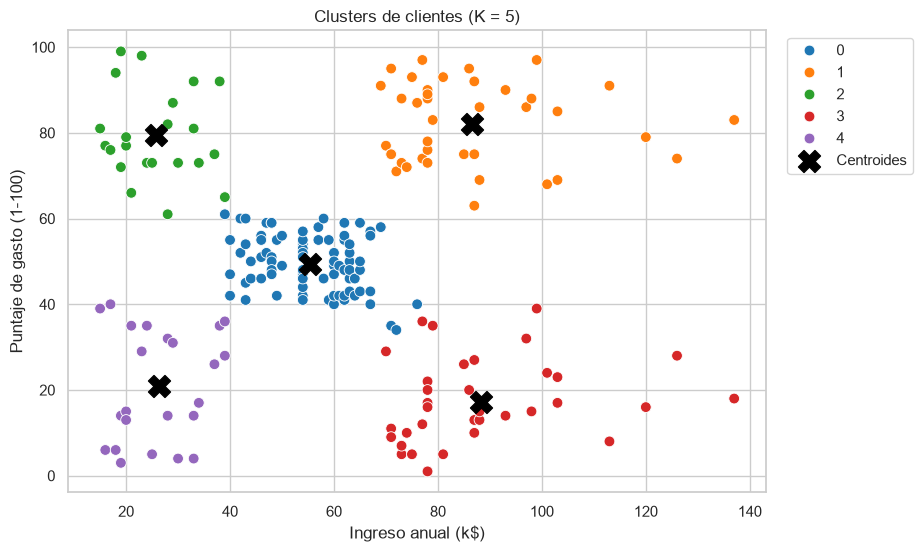

In [15]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Ingreso", y="Gasto", hue="Cluster", palette="tab10", s=60)
plt.scatter(centroides["Ingreso"], centroides["Gasto"], c="black", marker="X", s=250, label="Centroides")
plt.title("Clusters de clientes (K = 5)")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [16]:
resumen = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_media=("Edad", "mean"),
    Ingreso_medio=("Ingreso", "mean"),
    Gasto_medio=("Gasto", "mean"),
    Pct_mujeres=("Genero", lambda g: (g == "Female").mean() * 100),
).round(1)
resumen

,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres
Cluster,,,,,
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
2,22,25.3,25.7,79.4,59.1
3,35,41.1,88.2,17.1,45.7
4,23,45.2,26.3,20.9,60.9


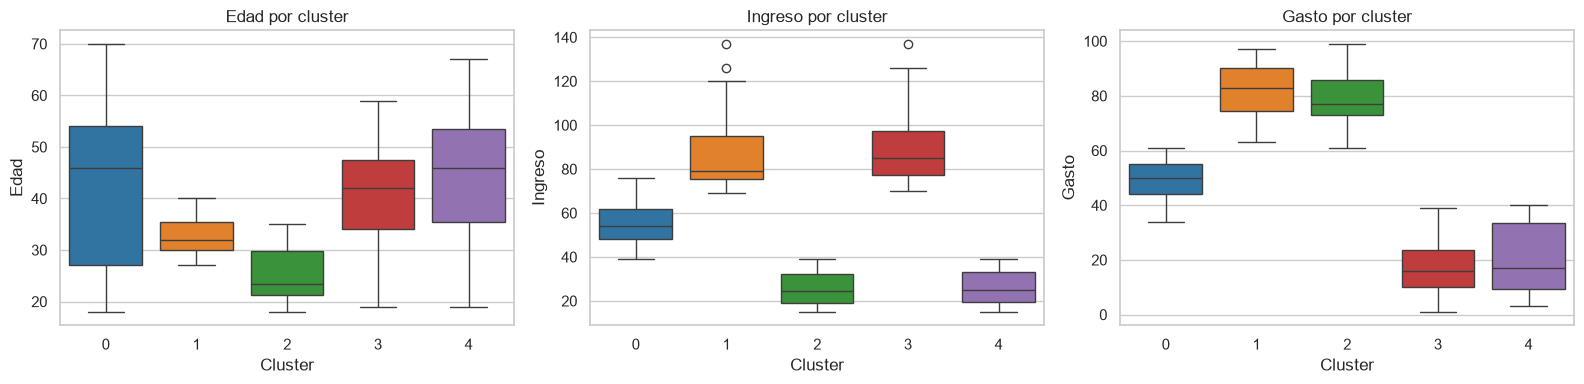

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Edad", "Ingreso", "Gasto"]):
    sns.boxplot(data=df, x="Cluster", y=col, hue="Cluster", palette="tab10", legend=False, ax=ax)
    ax.set_title(f"{col} por cluster")
plt.tight_layout()
plt.show()

### Preguntas – Parte 5

> Los números de cluster (0–4) los asigna K-Means arbitrariamente; la interpretación se basa en los
> centroides de la tabla anterior.

**¿Qué representa cada cluster?**

Cada cluster es un grupo de clientes con un **patrón similar de ingreso y gasto**, y su centroide es el
"cliente típico" del grupo:

| Cluster | Ingreso medio | Gasto medio | Edad media | Clientes | Descripción |
|---|---|---|---|---|---|
| 0 | ≈ 55 k$ | ≈ 50 | ≈ 43 | 81 | Ingreso medio y gasto medio (el grupo más grande) |
| 1 | ≈ 87 k$ | ≈ 82 | ≈ 33 | 39 | Ingreso alto y gasto alto |
| 2 | ≈ 26 k$ | ≈ 79 | ≈ 25 | 22 | Ingreso bajo pero gasto alto (los más jóvenes) |
| 3 | ≈ 88 k$ | ≈ 17 | ≈ 41 | 35 | Ingreso alto pero gasto bajo |
| 4 | ≈ 26 k$ | ≈ 21 | ≈ 45 | 23 | Ingreso bajo y gasto bajo (los de mayor edad) |

**¿Qué diferencias existen entre los grupos obtenidos?**

- **Ingreso:** separa claramente tres niveles: bajo (clusters 2 y 4, ≈ 26 k$), medio (cluster 0) y alto
  (clusters 1 y 3, ≈ 87 k$).
- **Gasto:** dentro de cada nivel extremo de ingreso hay un grupo que gasta mucho y otro que gasta poco.
  Los clusters 1 y 3 ganan prácticamente lo mismo, pero el 1 gasta ~5 veces más que el 3; igual ocurre
  entre el 2 y el 4. Es decir, **el ingreso por sí solo no explica el gasto**.
- **Edad (variable no usada para entrenar):** los grupos de gasto alto son más jóvenes (≈ 25–33 años) que los
  de gasto bajo (≈ 41–45 años), lo que confirma la correlación negativa Edad–Gasto vista en la Parte 1.
- **Tamaño:** el segmento promedio concentra ~40 % de los clientes; los otros cuatro tienen entre 22 y 39.
- **Género:** las proporciones son similares en todos los grupos (≈ 46–61 % mujeres), así que el género no
  es un diferenciador relevante.

## Parte 6 – Interpretación de Negocio

In [18]:
def asignar_perfil(ingreso, gasto):
    """Clasifica un centroide (en unidades originales) en un perfil de negocio."""
    if ingreso >= 70 and gasto >= 60:
        return "Alto valor"
    if ingreso >= 70 and gasto < 40:
        return "Con potencial"
    if ingreso < 40 and gasto < 40:
        return "Bajo valor"
    if ingreso < 40 and gasto >= 60:
        return "Gastador impulsivo"
    return "Promedio"

perfiles = {c: asignar_perfil(r.Ingreso, r.Gasto) for c, r in centroides.iterrows()}
df["Perfil"] = df["Cluster"].map(perfiles)
resumen["Perfil"] = resumen.index.map(perfiles)
resumen[["Perfil", "Clientes", "Edad_media", "Ingreso_medio", "Gasto_medio", "Pct_mujeres"]]

,Perfil,Clientes,Edad_media,Ingreso_medio,Gasto_medio,Pct_mujeres
Cluster,,,,,,
0,Promedio,81,42.7,55.3,49.5,59.3
1,Alto valor,39,32.7,86.5,82.1,53.8
2,Gastador impulsivo,22,25.3,25.7,79.4,59.1
3,Con potencial,35,41.1,88.2,17.1,45.7
4,Bajo valor,23,45.2,26.3,20.9,60.9


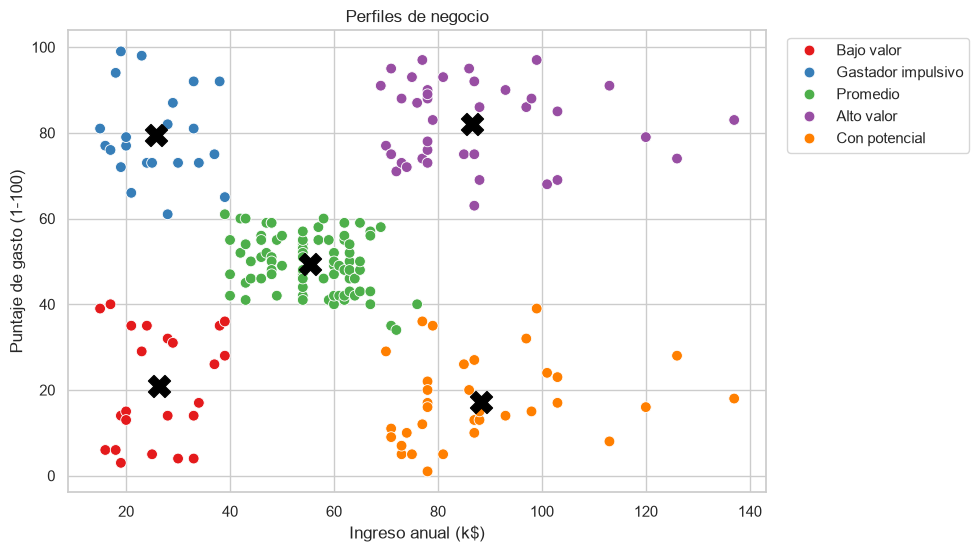

In [19]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Ingreso", y="Gasto", hue="Perfil", palette="Set1", s=60)
plt.scatter(centroides["Ingreso"], centroides["Gasto"], c="black", marker="X", s=250)
plt.title("Perfiles de negocio")
plt.xlabel("Ingreso anual (k$)")
plt.ylabel("Puntaje de gasto (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### Clasificación de los clusters en perfiles

| Perfil | Cluster | Ingreso | Gasto | Justificación |
|---|---|---|---|---|
| **Clientes de alto valor** | 1 | Alto | Alto | Tienen capacidad y la usan: son los que más ingresos generan al centro comercial. |
| **Clientes promedio** | 0 | Medio | Medio | El grupo más numeroso; comportamiento estable y moderado. |
| **Clientes de bajo valor** | 4 | Bajo | Bajo | Poca capacidad y poco gasto; aportan poco margen. |
| **Clientes con potencial** | 3 | Alto | Bajo | Tienen dinero pero no lo gastan aquí: es demanda no capturada. |
| *Gastador impulsivo* (perfil adicional) | 2 | Bajo | Alto | Jóvenes que gastan por encima de su ingreso; valiosos hoy pero con riesgo. |

Como K = 5 genera cinco grupos y la guía propone cuatro perfiles, el quinto grupo (ingreso bajo / gasto
alto) se identifica como un perfil adicional; desde la óptica de valor podría agruparse con los
"clientes con potencial" (por su edad joven y su potencial de crecimiento de ingreso) o con los de
"alto valor" (por su gasto actual), pero su comportamiento amerita una estrategia propia.

### Preguntas – Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

- **Alto valor (ingreso alto, gasto alto):** programas de fidelización premium (membresías VIP, acceso
  anticipado a lanzamientos, atención personalizada, eventos exclusivos). El objetivo es **retenerlos**:
  perder uno de estos clientes cuesta mucho.
- **Promedio (ingreso y gasto medios):** promociones regulares, programas de puntos, combos y
  *cross-selling* para aumentar el ticket promedio y la frecuencia de visita. Comunicación masiva
  (redes sociales, correo) por ser el grupo más grande.
- **Bajo valor (ingreso bajo, gasto bajo):** campañas de bajo costo enfocadas en precio: descuentos,
  marcas propias, temporadas de liquidación. No conviene invertir mucho presupuesto en adquisición aquí.
- **Con potencial (ingreso alto, gasto bajo):** investigar por qué no compran (encuestas, análisis de la
  oferta). Ofrecer productos de mayor calidad/marcas de lujo, experiencias personalizadas, servicios de
  conveniencia (personal shopper, envío a domicilio) y promociones de "primera compra" en categorías premium.
- **Gastador impulsivo (ingreso bajo, gasto alto, jóvenes):** marketing digital y en redes sociales,
  tendencias y moda a precios accesibles, opciones de pago a plazos responsables; fidelizarlos desde ahora
  ya que su ingreso probablemente aumentará con los años.

**¿Qué segmento representa mayor oportunidad de crecimiento?**

Los **clientes con potencial (cluster 3)**. Son 35 clientes (17.5 %) con un ingreso medio de ≈ 88 k$
—igual al del segmento de alto valor— pero con un puntaje de gasto de solo ≈ 17 frente a ≈ 82. Ya tienen la
capacidad de compra; el problema es de oferta, experiencia o comunicación, no de dinero. Convertir aunque
sea una parte de ellos en compradores frecuentes tendría el mayor impacto en ventas por cliente. En
segundo lugar, el segmento promedio es una buena oportunidad por volumen (81 clientes).

## Parte 7 – Despliegue con Streamlit

Se guardan el escalador y el modelo entrenados para que la aplicación use exactamente el mismo modelo del
cuaderno. La aplicación está en `app.py` y se ejecuta con:

```bash
streamlit run app.py
```

Permite visualizar el método del codo y la silueta, mostrar los clusters generados, ingresar un nuevo
cliente y clasificarlo automáticamente en un cluster/perfil.

In [20]:
joblib.dump({"scaler": scaler, "kmeans": kmeans, "features": FEATURES, "perfiles": perfiles},
            "modelo_kmeans.joblib")

# Ejemplo de clasificación de un cliente nuevo
nuevo = pd.DataFrame([[90, 20]], columns=FEATURES)
c = kmeans.predict(scaler.transform(nuevo.values))[0]
print(f"Cliente con ingreso 90 k$ y gasto 20 -> Cluster {c} ({perfiles[c]})")

Cliente con ingreso 90 k$ y gasto 20 -> Cluster 3 (Con potencial)
